In [1]:
import torch
import lightning as L
from lightning.pytorch.loggers import TensorBoardLogger
from lightning.pytorch.callbacks import ModelCheckpoint
from matplotlib import pyplot as plt

import importlib
from data_functions import dataset, utils_data
from data_functions.collate import pad_nextoso_collate
from src import LTAE, lightning_module, utils_model

importlib.reload(lightning_module)
PATH_TO_DATA_s2 = "/home/hkerino/Documents/nextoso-dataset/data/10m/s2"
PATH_TO_DATA_label = "/home/hkerino/Documents/nextoso-dataset/data/10m/labels"

In [2]:
batch_size = 8

dt_train = dataset.next_oso_Dataset(
    path_s2=PATH_TO_DATA_s2, path_label=PATH_TO_DATA_label, norm=True, folds=[1]
)
dl_train = torch.utils.data.DataLoader(
    dt_train, batch_size=batch_size, collate_fn=pad_nextoso_collate, shuffle=True
)

dt_val = dataset.next_oso_Dataset(
    path_s2=PATH_TO_DATA_s2, path_label=PATH_TO_DATA_label, norm=True, folds=[2]
)
dl_val= torch.utils.data.DataLoader(
    dt_val, batch_size=batch_size, collate_fn=pad_nextoso_collate, shuffle=True
)

dt_test = dataset.next_oso_Dataset(
    path_s2=PATH_TO_DATA_s2, path_label=PATH_TO_DATA_label, norm=True, folds=[3]
)
dl_test = torch.utils.data.DataLoader(
    dt_test, batch_size=batch_size, collate_fn=pad_nextoso_collate, shuffle=True
)

In [3]:
(x, dates, mask), y = dl_test.__iter__().__next__()
print(x.shape)
print(dates.shape)
print(mask.shape)
print(y.shape)

torch.Size([8, 10, 148, 128, 128])
torch.Size([8, 148])
torch.Size([8, 148, 128, 128])
torch.Size([8, 128, 128])


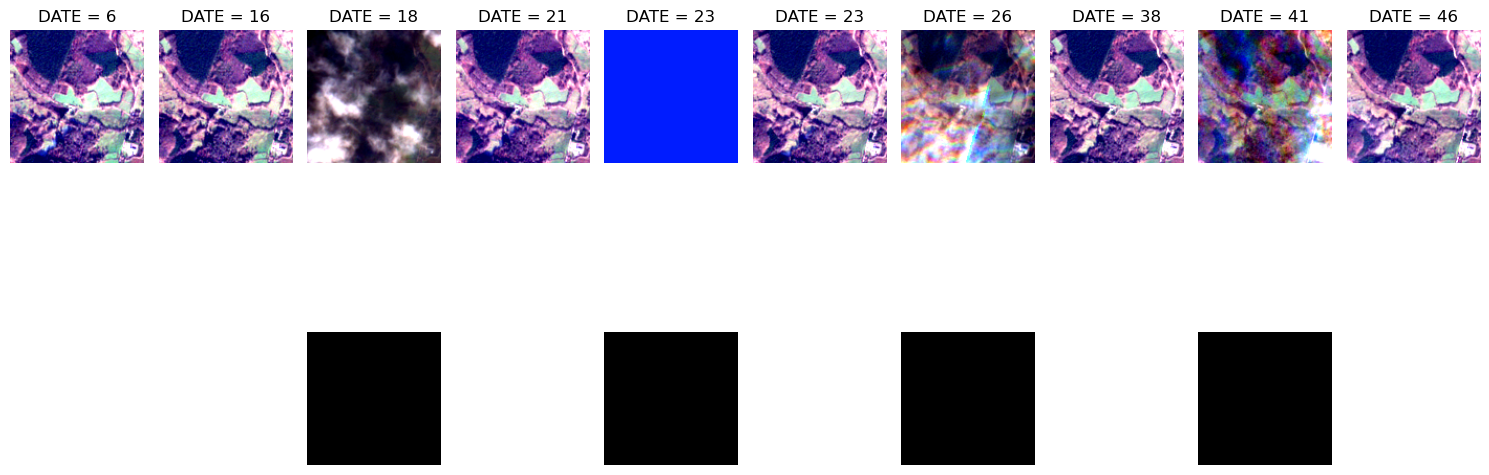

In [4]:
idx_batch = 3
lenght, first_date = 10, 0
fig, axes1 = plt.subplots(2,lenght, figsize=(15,8))
for t in range(lenght):
    # Affichage de l'image RGB
    axes1[0, t].imshow(utils_data.array_to_RGB(x[idx_batch, :,first_date + t, :, :], norm=True))
    axes1[0, t].set_title(f"DATE = {dates[idx_batch, first_date + t].numpy()}")
    axes1[0, t].axis("off")
    # Affichage du masque
    axes1[1, t].imshow(
        mask[idx_batch, first_date + t, :, :], cmap="Greys", vmin=0, vmax=1
    )
    axes1[1, t].axis("off")
plt.tight_layout()

In [5]:
LTAE_encoder = LTAE.LTAE2d(
    in_channels=10,
    n_head=5,
    d_k=4,
    d_model=10,
    T=1000,
    return_att=False,
    positional_encoding=True,
)

MLP_Decoder = utils_model.MLPDecoder(mlp=[10, 32, 25], dropout=0.2)
# Select device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print(f"GPU utilisé : {torch.cuda.get_device_name(0)}")
else:
    print("Périphérique utilisé : cpu")

print(f"Périphérique PyTorch : {device}")

Périphérique utilisé : cpu
Périphérique PyTorch : cpu


In [6]:
importlib.reload(lightning_module)

classifier = lightning_module.classifier(LTAE_encoder, MLP_Decoder, batch_size=4)

checkpoint_callback = ModelCheckpoint(
    dirpath="/home/hkerino/Documents/models_on_nextoso/logs/LTAE"
)
tb_logger = TensorBoardLogger("logs/", name="LTAE")

trainer = L.Trainer(logger=tb_logger, callbacks=[checkpoint_callback], max_epochs=5)

trainer.fit(model=classifier, train_dataloaders=dl_train, val_dataloaders=dl_val)
trainer.test(model=classifier, dataloaders=dl_test)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.14/site-packages/lightning/pytorch/loops/utilities.py:73: `max_epochs` was not set. Setting it to 1000 epochs. To train without an epoch limit, set `max_epochs=-1`.
/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.14/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory /home/hkerino/Documents/models_on_nextoso/logs/LTAE exists and is not empty.

  | Name       | Type               | Params | Mode  | FLOPs
------------------------------------------------------------------
0 | encoder    | LTAE2d             | 350    | train | 0    
1 | decoder    | MLPDecode

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:485: Your `val_dataloader`'s sampler has shuffling enabled, it is strongly recommended that you turn shuffling off for val/test dataloaders.
/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.14/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=21` in the `DataLoader` to improve performance.
/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.14/site-packages/lightning/pytorch/utilit

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]


Detected KeyboardInterrupt, attempting graceful shutdown ...


SystemExit: 1

/home/hkerino/Documents/models_on_nextoso/.pixi/envs/default/lib/python3.14/site-packages/IPython/core/interactiveshell.py:3709: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)
